# AP 155 Lab Exercise
---
## Exercise 8: Minimization

_Instructions_: 
- **Report figure:** A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm.  
- **Report discussion:** What happens if a number other than the golden ratio is used to perform the *golden* section search algorithm?
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Botron, Christan Jake
- _Student No._: 2024-10168
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view?usp=sharing) (Note: percentages may still be tweaked)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_:_

---
## Section 1: Report

### Report figure

<img src="golden_search.png" alt="Alt text" width=45%>


Figure 1. Numerical estimation of local extrema for $\phi(x)$ (left) and $f(x)$ (right) using the Golden Section Search algorithm, alongside their respective analytical derivatives (bottom row), showing the corresponding roots. The estimated local extrema plotted on the original functions perfectly align with the roots (where $y=0$) of their respective derivative functions, visually confirming that the algorithm successfully located the critical points without needing to evaluate the derivatives directly.


### Report discussion

As seen in Figure 1,  If a number other than the golden ratio (i.e., $\varphi \approx 1.618$) is used to define the interior test points, the algorithm should essentially still converge to the local extrema. However, it completely loses its primary advantage, which is point reusability. Based on Gezerlis, the golden ratio is uniquely chosen because its geometric proportions allow the remaining sub-interval to scale perfectly with the parent interval. In other words, when the search boundaries shrink, one of our previous interior test points automatically aligns to become a new interior point for the next iteration (meaning we only need one new function evaluation per loop). On the other hand, if we were to use an arbitrary ratio, say $0.5$, the nested intervals lose this proportional symmetry, and we are forced to calculate two entirely new function evaluations at every single step. Ultimately, even if an arbitrary ratio physically narrows the bracket faster, doubling the function calls makes the overall algorithm drastically slower and computationally expensive.

### Other comments
- I have no other comments.


---
## Section 2: Code

In [92]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Minimization

Consider the following equations:

Eq. 5.91
$$
\phi(x) = x^4 - 9x^3 + 25x^2 - 24x + 4
$$

Eq. 5.145
$$
f(x) = -x^5 + 4x^4 - 4x^3 + x^2 e^x - 2x^2 - 4xe^x + 8x + 4e^x - 8
$$


1. Plot each of the functions. Get a rough estimate of the local minima and maxima
2. Implement 5.5.2.2 (golden section search), then determine the local minima and maxima of Eq. 5.91 and Eq. 5.145.
3. Report figure: A 2 by 2 figure plot. Upper row contains the plot of the actual functions. Lower row contains a plot of their derivatives. Use markers to plot the found local extrema by the golden section search algorithm. 

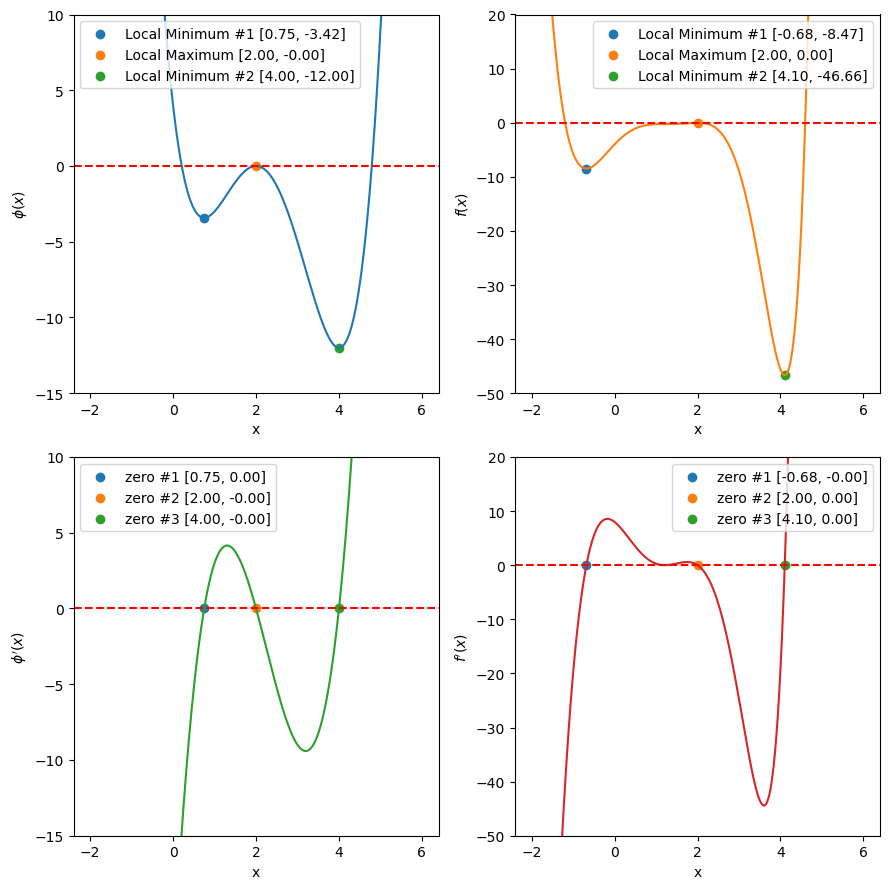

In [96]:
def phi(x):
    return x**4 - 9*x**3 + 25*x**2 - 24*x + 4
def phi_prime(x):
    return 4*x**3 - 27*x**2 + 50*x - 24
def f(x):
    return -x**5 + 4*x**4 - 4*x**3 + x**2 * np.exp(x) - 2*x**2 - 4*x*np.exp(x) + 8*x + 4*np.exp(x) - 8
def f_prime(x):
    return -5*x**4 + 16*x**3 - 12*x**2 + (x**2*np.exp(x) + np.exp(x)*2*x) - 4*x - 4*(x*np.exp(x) + np.exp(x)) + 8 + 4*np.exp(x)
    
def golden(func, x0, x1, tol=1.e-8): #reference: Gezerlis; x0 is the initial left bound, x1 is the initial right bound
    gr = 0.5*(1+np.sqrt(5)) #golden ratio

    while abs(x1-x0) > tol:
        x2 = x0 + (x1-x0)/(gr+1) #new test left bound offset by a term (x1-x0)/(gr+1)
        x3 = x0 + (x1-x0)*gr / (gr+1) #new test right bound offset by a term (x1-x0)*gr/(gr+1)

        if func(x3) < func(x2): #when f(x3) < f(x2), that means that we are going "downhill" towards the minima (i.e., x2 is to the left of the minima). Thus, we set x2 as the new "left bound," replacing x0 
            x0 = x2
        else:  #else, when f(x3) > f(x), we are going "uphill" away from the minima. Thus, we can set the new right bound to be x3 from x1.
            x1 = x3
    return (x0+x1)/2

#og functions and the plot of their derivative functions
x_vals = np.linspace(-2, 6, 1000)
phi_vals = phi(x_vals)
phi_prime_vals = phi_prime(x_vals)
f_vals = f(x_vals)
f_prime_vals = f_prime(x_vals)

#identifying extremas
phi_1 = golden(phi, 0, 1.5)
phi_2 = golden(lambda x: -phi(x), 1.5, 3.0) #basically reverses the graph s.t. the crests become troughs for our algorithm
phi_3 = golden(phi, 3.0, 5.0)

f_1 = golden(f, -2.0, 0.0)
f_2 = golden(lambda x: -f(x), 0.0, 3.0)
f_3 = golden(f, 3.0, 5.0)

fig, axs = plt.subplots(2, 2, figsize = (9,9))

axs[0, 0].plot(x_vals, phi_vals)
axs[0, 0].set_xlabel(r'x')
axs[0, 0].set_ylabel(r'$\phi(x)$')
axs[0, 0].scatter(phi_1, phi(phi_1), label=f'Local Minimum #1 [{phi_1:.2f}, {phi(phi_1):.2f}]')
axs[0, 0].scatter(phi_2, phi(phi_2), label=f'Local Maximum [{phi_2:.2f}, {phi(phi_2):.2f}]')
axs[0, 0].scatter(phi_3, phi(phi_3), label=f'Local Minimum #2 [{phi_3:.2f}, {phi(phi_3):.2f}]')
axs[0, 0].set_ylim(-15, 10)
axs[0, 0].axhline(y=0, linestyle="--", color='red')
axs[0, 0].legend()

axs[0, 1].plot(x_vals, f_vals, 'tab:orange')
axs[0, 1].set_xlabel(r'x')
axs[0, 1].set_ylabel(r'$f (x)$')
axs[0, 1].scatter(f_1, f(f_1), label=f'Local Minimum #1 [{f_1:.2f}, {f(f_1):.2f}]')
axs[0, 1].scatter(f_2, f(f_2), label=f'Local Maximum [{f_2:.2f}, {f(f_2):.2f}]')
axs[0, 1].scatter(f_3, f(f_3), label=f'Local Minimum #2 [{f_3:.2f}, {f(f_3):.2f}]')
axs[0, 1].set_ylim(-50, 20)
axs[0, 1].axhline(y=0, linestyle="--", color='red')
axs[0, 1].legend()

axs[1, 0].plot(x_vals, phi_prime_vals, 'tab:green')
axs[1, 0].set_xlabel(r'x')
axs[1, 0].set_ylabel(r"$\phi'(x)$")
axs[1, 0].scatter(phi_1, phi_prime(phi_1), label=f'zero #1 [{phi_1:.2f}, {phi_prime(phi_1):.2f}]')
axs[1, 0].scatter(phi_2, phi_prime(phi_2), label=f'zero #2 [{phi_2:.2f}, {phi_prime(phi_2):.2f}]')
axs[1, 0].scatter(phi_3, phi_prime(phi_3), label=f'zero #3 [{phi_3:.2f}, {phi_prime(phi_3):.2f}]')
axs[1, 0].set_ylim(-15, 10)
axs[1, 0].axhline(y=0, linestyle="--", color='red')
axs[1, 0].legend()

axs[1, 1].plot(x_vals, f_prime_vals, 'tab:red')
axs[1, 1].set_xlabel(r'x')
axs[1, 1].set_ylabel(r"$f ' (x)$")
axs[1, 1].scatter(f_1, f_prime(f_1), label=f'zero #1 [{f_1:.2f}, {f_prime(f_1):.2f}]')
axs[1, 1].scatter(f_2, f_prime(f_2), label=f'zero #2 [{f_2:.2f}, {f_prime(f_2):.2f}]')
axs[1, 1].scatter(f_3, f_prime(f_3), label=f'zero #3 [{f_3:.2f}, {f_prime(f_3):.2f}]')
axs[1, 1].set_ylim(-50, 20)
axs[1, 1].axhline(y=0, linestyle="--", color='red')
axs[1, 1].legend()

plt.tight_layout()
plt.savefig("golden_search.png", bbox_inches="tight", dpi=300)
fig.show()

#### Problem 1 code summary

To start, I first defined the functions I needed (i.e., $\phi(x)$ and $f(x)$), as well as their derivatives for demonstration purposes (not used in the algorithm). Then, I used the golden section search algorithm to numerically approximate the local extrema of the functions without using their derivatives. The algorithm was essentially the same as the bisection method in the previous exercise, where we take two test $x's$ (i.e., $x_n$ and $x_{n+1}$) and check where they are relative to the extrema by comparing their function output $f(x_n)$ and $f(x_{n+1})$. Finally, for the identification of the extrema, it was straightforward for the local minima, but for the local maxima, I had to take the negative of the function in order to transform them into local minima for the algorithm to work.

